# Tarea 26: Clustering jerarquico

In [3]:
# load libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import normalize

# libraries for clustering 
import scipy.cluster.hierarchy as sch


In [4]:
# load amazon data from excell file
df = pd.read_excel('Amazon.xlsx')
df.sample(5)

,Unnamed: 0,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
60,Marian,155,95,495,225,26,31,19,24,39
42,Judith,245,115,465,225,36,13,31,295,38
45,Larissa,25,125,47,23,37,14,315,3,39
78,Myron,5,95,355,225,15,31,495,165,24
66,Maryna,21,125,46,31,33,39,365,3,44


In [13]:
# normalize values 
df_numerico = df.drop(columns= ['Unnamed: 0'])
data_scaled = normalize(df_numerico)
df_scaled = pd.DataFrame(data_scaled, columns=df.columns.drop('Unnamed: 0'))
df_scaled.sample(5)

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
11,0.300817,0.016969,0.701906,0.035481,0.004628,0.038566,0.640200,0.038566,0.049365
17,0.417496,0.015337,0.656066,0.366374,0.057938,0.025561,0.502700,0.047714,0.042602
69,0.175446,0.282239,0.633130,0.039666,0.004577,0.035089,0.694154,0.036615,0.051871
2,0.057235,0.087535,0.959520,0.010100,0.144770,0.090902,0.138036,0.087535,0.111102
15,0.028788,0.001693,0.821309,0.397954,0.045722,0.028788,0.040642,0.397954,0.057576


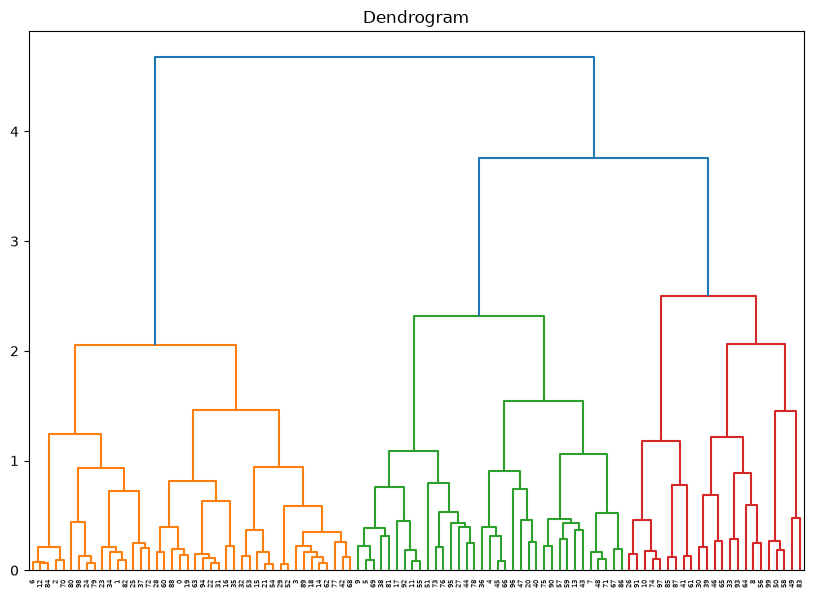

In [19]:

plt.figure(figsize=(10, 7))
plt.title('Dendrogram')
dend = sch.dendrogram(sch.linkage(df_scaled, method='ward'))


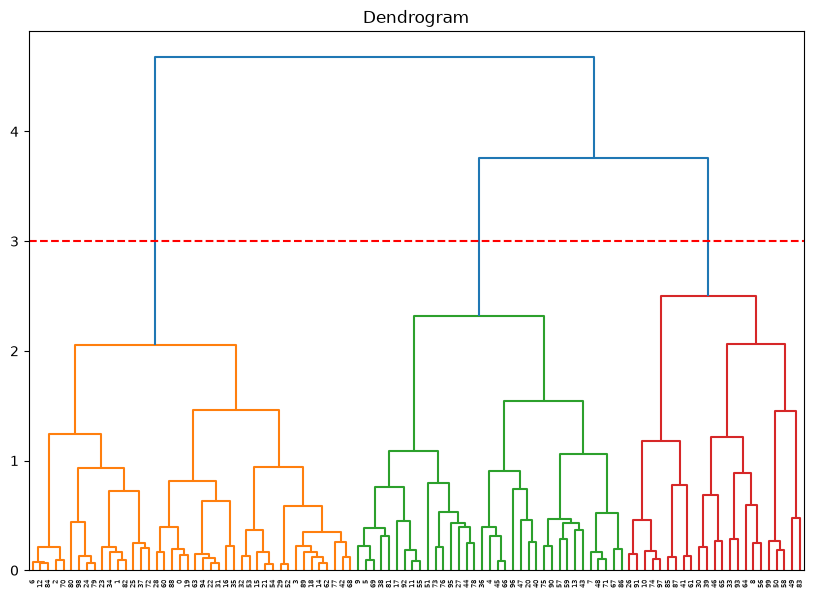

In [ ]:
number_of_optimal_cluster = len(set(dend['color_list'])) - 1 # Number optimal calculated from the color list
plt.figure(figsize=(10, 7))
plt.title('Dendrogram')
dend = sch.dendrogram(sch.linkage(data_scaled, method= 'ward'))
plt.axhline(y = number_of_optimal_cluster, color = 'r', linestyle = '--')


In [29]:
from sklearn.cluster import AgglomerativeClustering
cluster = AgglomerativeClustering(n_clusters=number_of_optimal_cluster, metric = 'euclidean', linkage= 'ward')
labels = cluster.fit_predict(data_scaled)

df['Cluster'] = labels

# Grafica de velocidad de entrega vs. numero de estrellas 

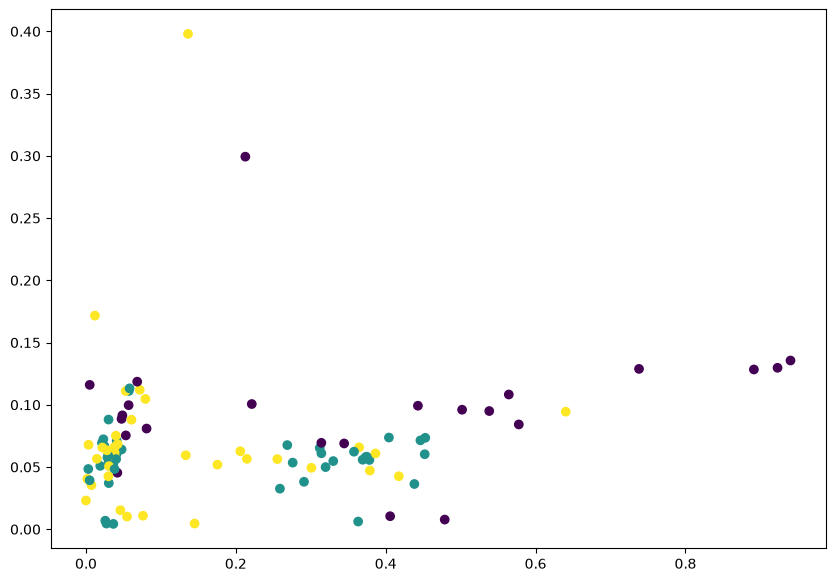

In [50]:
plt.figure(figsize=(10, 7))
plt.scatter(data_scaled[:, 0], data_scaled[:, -1], c = cluster.labels_)

# Grafica de Reduccion de dimencionalidad PCA

In [45]:
from sklearn import decomposition

pca = decomposition.PCA(n_components=2)
pca.fit(data_scaled)
campos = pca.transform(data_scaled)
campos

array([[ 0.39993219, -0.06035374],
       [ 0.40829583,  0.06402268],
       [ 0.49703182,  0.35955286],
       [ 0.33996675, -0.18434501],
       [-0.58207751,  0.38797653],
       [-0.1723403 ,  0.52962573],
       [ 0.56528441,  0.33770585],
       [-0.5335887 , -0.06994712],
       [-0.09981604, -0.47165743],
       [-0.22195207,  0.56503313],
       [-0.08274005, -0.39712712],
       [ 0.00143465,  0.48936583],
       [ 0.57292039,  0.35927774],
       [-0.51350639, -0.01301312],
       [ 0.35272162, -0.20639728],
       [ 0.4688626 , -0.0168001 ],
       [ 0.25142488, -0.04599019],
       [ 0.05456876,  0.22302796],
       [ 0.36123131, -0.20553368],
       [ 0.41087067, -0.02173183],
       [-0.54207892,  0.03308916],
       [ 0.5138909 ,  0.0900875 ],
       [ 0.4284552 ,  0.0601418 ],
       [ 0.42320562,  0.09945498],
       [ 0.42610215, -0.06318626],
       [ 0.10615885,  0.20376697],
       [-0.19058214, -0.3966612 ],
       [ 0.096838  ,  0.33104612],
       [ 0.51505714,

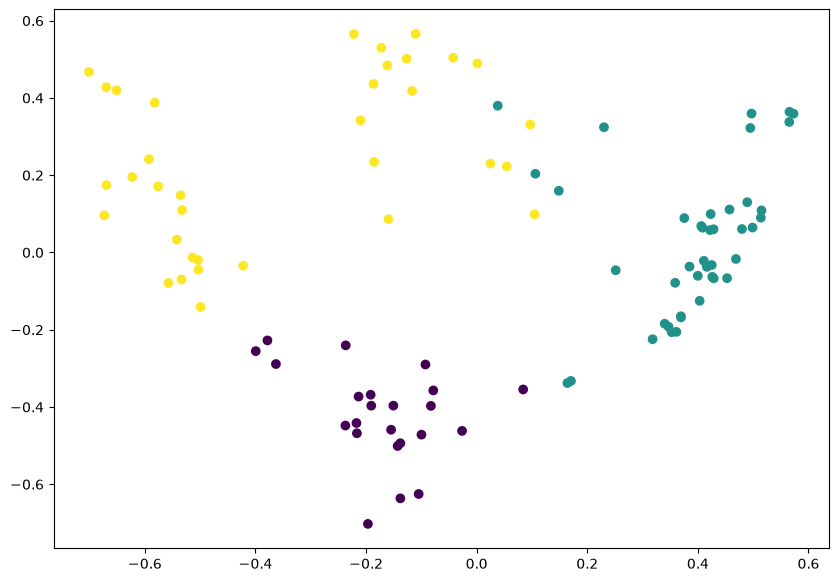

In [48]:
plt.figure(figsize=(10, 7))
plt.scatter(campos[:,0], campos[:,1], c = cluster.labels_)

En la primera grafica se ve que los cluster no tienen una separacion muy clara por lo que se hace uso de la la reduccion de dimensionalidad para lograr visualizar los clusters de una forma mas general

In [ ]:
df.sample(5)

,Unnamed: 0,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas,Cluster
8,Xavier,275,8,47,235,35,3,38,27,48,0
9,Gabriel,2,175,325,3,37,32,435,27,39,2
24,Flavia,255,7,435,24,33,26,19,245,34,1
64,Martha,55,1,36,235,16,32,5,17,25,0
61,Marianna,255,95,46,29,36,23,225,305,45,0


In [58]:

print(df[['Unnamed: 0', 'Cluster']])

   Unnamed: 0  Cluster
0        Adam        1
1        Anna        1
2     Bernard        1
3      Edward        1
4      Emilia        2
..        ...      ...
95     Teofan        2
96     Teofil        2
97    Teofila        0
98       Teon        1
99     Teresa        0

[100 rows x 2 columns]


## Productos recomendados a Salome

In [70]:
cluster_salome = df[df['Unnamed: 0']=='Salome']['Cluster'].values[0]

clients_with_same_cluster = df[df['Cluster'] == cluster_salome]  
print(f'El cluster {cluster_salome} son los productos recomendados a Salome, quien ya compraron ese tipo de productos son:')
print(clients_with_same_cluster['Unnamed: 0'])

El cluster 2 son los productos recomendados a Salome, quien ya compraron ese tipo de productos son:
4        Emilia
5        Fabian
7         Frank
9       Gabriel
11        Henry
13     Isabelle
17      Eugenia
20      Evdokia
27     Florence
36     Jeremiah
38      Joachim
40     Santiago
43       Justin
44       Kalyna
45      Larissa
47         Leon
48      Leonard
51          Leo
55    Magdalyna
57       Marcel
59        Maria
66       Maryna
67      Matthew
69         Maya
71      Melania
73      Michael
75         Mina
76       Monica
78        Myron
81       Salome
86    Sebastian
90      Susanna
92    Sylvester
95       Teofan
96       Teofil
Name: Unnamed: 0, dtype: str


## Productos recomendados a Stephania

In [69]:
cluster_stephania = df[df['Unnamed: 0']=='Stephania']['Cluster'].values[0]

clients_with_same_cluster = df[df['Cluster'] == cluster_stephania]  
print(f'El cluster {cluster_stephania} son los productos recomendados a Stephania, quien ya compraron ese tipo de productos son:')
print(clients_with_same_cluster['Unnamed: 0'])

El cluster 1 son los productos recomendados a Stephania, quien ya compraron ese tipo de productos son:
0            Adam
1            Anna
2         Bernard
3          Edward
6          Philip
12          Irene
14        Isidore
15         Joseph
16         Eugene
18         Eunice
19            Eva
21          Fedir
22          Felix
23         Fialka
24         Flavia
25          Flora
28         Hannah
29          Helen
31         Hilary
32        Lourdes
34           Ivan
35          Jacob
37         Jervis
42         Judith
52         Louise
53        Lubomyr
54          Lydia
60         Marian
62        Markian
63          Marko
68          Maura
70    Maximillian
72      Methodius
77         Mykyta
79       Myroslav
80      Myroslava
82         Samuel
84          Sarah
88        Stephan
89      Stephania
94       Theodore
98           Teon
Name: Unnamed: 0, dtype: str


## Productos recomendados a Lydia

In [71]:
## Productos recomendados a Lydia
cluster_lydia = df[df['Unnamed: 0']=='Lydia']['Cluster'].values[0]

clients_with_same_cluster = df[df['Cluster'] == cluster_lydia]  
print(f'El cluster {cluster_lydia} son los productos recomendados a Lydia, quien ya compraron ese tipo de productos son:')
print(clients_with_same_cluster['Unnamed: 0'])

El cluster 1 son los productos recomendados a Lydia, quien ya compraron ese tipo de productos son:
0            Adam
1            Anna
2         Bernard
3          Edward
6          Philip
12          Irene
14        Isidore
15         Joseph
16         Eugene
18         Eunice
19            Eva
21          Fedir
22          Felix
23         Fialka
24         Flavia
25          Flora
28         Hannah
29          Helen
31         Hilary
32        Lourdes
34           Ivan
35          Jacob
37         Jervis
42         Judith
52         Louise
53        Lubomyr
54          Lydia
60         Marian
62        Markian
63          Marko
68          Maura
70    Maximillian
72      Methodius
77         Mykyta
79       Myroslav
80      Myroslava
82         Samuel
84          Sarah
88        Stephan
89      Stephania
94       Theodore
98           Teon
Name: Unnamed: 0, dtype: str


La recomendacion de los productos se hace de acuerdo al cluster al que pertenecen los usuarios. Por ejemplo, Salome tiene asignado un cluster 2 y se le prodrian recomendar productos como los que que compro Emilia, Fabian, Frank, Gabriel, Henry, Isabelle, etcetera.